# Naive Vanishing Point Detector for Comparison with traditional VP techniques

In [2]:
# Libraries
import sys
import os
import numpy as np
import keras
import math
from keras.layers import Conv2D, MaxPooling2D, BatchNormalization, Flatten, Dense, Reshape, InputLayer, Dropout
from keras.models import Sequential
import tensorflow as tf
import tensorflow_io as tfio
import pandas as pd
from PIL import Image, ImageDraw, ImageFilter
import matplotlib.pyplot as plt
import scipy.io as sio 

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.24.3
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


# Dataset
We will be using indoor images from the NYU Depth dataset, (we will not be using the depth images). We will also be using labels from NYU VP, which labels lines cooresponding to the vanishing point in the NYU Depth images.

In [3]:
# Directories
lbl_pth = "../input/nyu-vp/data/"
img_pth = "../input/nyu-depth-v2/nyu_data/data/"


# CSV of image paths and corresponding labels for 654 rows
df = pd.read_csv(os.path.join(img_pth, "nyu2_test.csv"), nrows=654, header=None, names=["rgb","lines"])
df["lines"] = df.index
df["lines"] = df["lines"].apply(lambda x: "%slabelled_lines_%04d.csv" % (lbl_pth, int(df["rgb"][x].lstrip("data/nyu2_test/").rstrip("_colors.png"))))
df["rgb"] = df["rgb"].apply(lambda x: f"../input/nyu-depth-v2/nyu_data/{x}")
print(df.shape)
df.head(5)

(654, 2)


,rgb,lines
0,../input/nyu-depth-v2/nyu_data/data/nyu2_test/...,../input/nyu-vp/data/labelled_lines_0000.csv
1,../input/nyu-depth-v2/nyu_data/data/nyu2_test/...,../input/nyu-vp/data/labelled_lines_0001.csv
2,../input/nyu-depth-v2/nyu_data/data/nyu2_test/...,../input/nyu-vp/data/labelled_lines_0008.csv
3,../input/nyu-depth-v2/nyu_data/data/nyu2_test/...,../input/nyu-vp/data/labelled_lines_0013.csv
4,../input/nyu-depth-v2/nyu_data/data/nyu2_test/...,../input/nyu-vp/data/labelled_lines_0014.csv


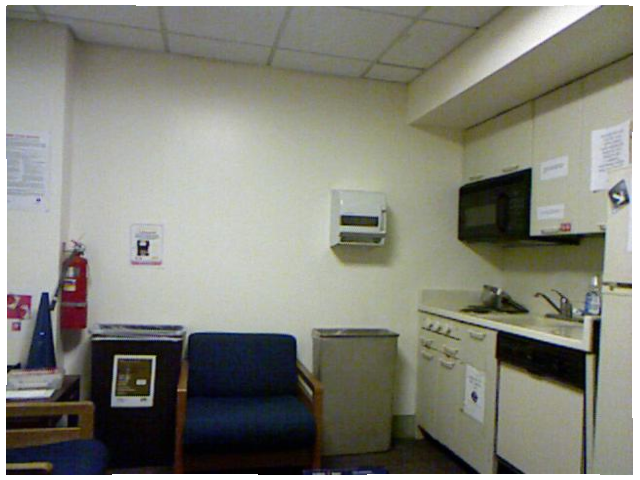

In [4]:
# Showing image
Image.open(df["rgb"][0])

In [5]:
# Showing label format
example_label = pd.read_csv(df["lines"][0], sep=' ')
example_label.head()

,idx,line1_x1,line1_y1,line1_x2,line1_y2,line2_x1,line2_y1,line2_x2,line2_y2,line3_x1,...,line6_x2,line6_y2,line7_x1,line7_y1,line7_x2,line7_y2,line8_x1,line8_y1,line8_x2,line8_y2
0,0,67,28,57,360,606,230,594,448,419,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,81,39,405,82,194,333,289,335,367,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,410,124,589,9,269,61,290,6,418,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


CENTER VP: [105.16170410547466, 277.66775959156826]
Vanishing point 1
Line 1: (191.0,197.0), (392.0,5.0) 
Line 2: (74.0,7.0), (95.0,188.0) 
Line 3: (219.0,290.0), (483.0,324.0) 
Line 4: (238.0,378.0), (367.0,473.0) 
Vanishing point 2
Line 1: (9.0,37.0), (258.0,78.0) 
Line 2: (91.0,92.0), (233.0,111.0) 
Line 3: (109.0,217.0), (181.0,220.0) 
Line 4: (20.0,186.0), (77.0,190.0) 
Vanishing point 3
Line 1: (187.0,174.0), (186.0,403.0) 
Line 2: (394.0,100.0), (395.0,235.0) 
Line 3: (313.0,149.0), (313.0,281.0) 
Line 4: (81.0,197.0), (79.0,381.0) 
Line 5: (113.0,231.0), (111.0,368.0) 


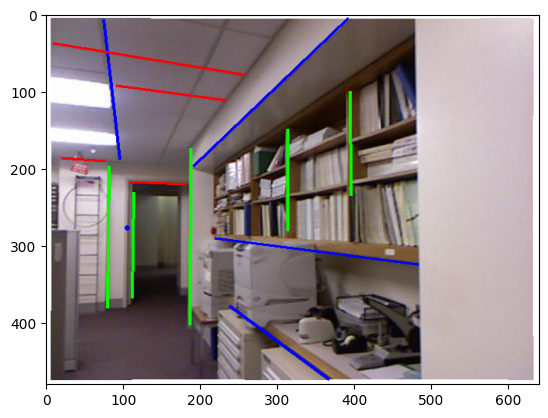

In [6]:
# Intersect function by user kevinkayaks at https://stackoverflow.com/questions/52088966/nearest-intersection-point-to-many-lines-in-python
def intersect(P0,P1):
    # generate all line direction vectors 
    n = (P1-P0)/np.linalg.norm(P1-P0,axis=1)[:,np.newaxis] # normalized
    # generate the array of all projectors 
    projs = np.eye(n.shape[1]) - n[:,:,np.newaxis]*n[:,np.newaxis]  # I - n*n.T
    # generate R matrix and q vector
    R = projs.sum(axis=0)
    q = (projs @ P0[:,:,np.newaxis]).sum(axis=0)
    # solve the least squares problem for the intersection point p: Rp = q
    try:
        p = np.linalg.lstsq(R,q,rcond=None)[0]
        return p
    except:
        p = None
        return p

# Method that gets vanishing point from labels
def get_vps(lbl_pth):
    lbl = pd.read_csv(lbl_pth, sep=' ').values
    vps = []
    for row in lbl: # each vanishing point
        P0, P1 = [], []
        for i in range(1, len(row)-1, 4):
            if pd.isnull(row[i+3]): continue
            x1, y1, x2, y2 = float(row[i]), float(row[i+1]), float(row[i+2]), float(row[i+3])
            P0.append([x1, y1])
            P1.append([x2, y2])
        #print("P0",P0)
        #print("P1",P1)
        vps.append(intersect(np.array(P0), np.array(P1)))
    #print(vps)
    return vps

def center_vp(lbl_path):
    vps = get_vps(lbl_path)
    if not vps:
        return [150,150]
    
    dist = {}
    i=0
    for vp in vps:
        if vp is None:
            return [150,150]
        dist[i] = math.sqrt(((150-vp[0])**2) + ((150-vp[1])**2)) # distance to center
            
    hor = min(dist, key=dist.get) # Closest to center
    
    return [vps[hor][0,0], vps[hor][1,0]]
    
            
# Display image with lines and vanishing points
def display_lines(img_pth, lbl_pth):
    lbl = pd.read_csv(lbl_pth, sep=' ').values # line labels
    img = Image.open(img_pth) # image
    vps = get_vps(lbl_pth)
    
    draw = ImageDraw.Draw(img)
    col = [(0,0,255),(255,0,0),(0,255,0),(255, 255, 0),(0,255,255),(255,255,255)]
    #print(vps)
    # Draw vanishing points
    c = 0
    for i in range(0, len(vps), 2):
        if vps[i] is None:
            continue
        x, y = vps[i][0], vps[i][1]
        #print(f"vp1 at {x},{y}")
        draw.ellipse((x-3,y-3, x+3, y+3), fill=col[c])
        c += 1
    
    # Draw lines
    c = 0
    for row in lbl:
        print(f"Vanishing point {c+1}")
        for i in range(1, len(row)-1, 4):
            # Get coordinates from csv file
            if pd.isnull(row[i+3]): continue
            x1, y1, x2, y2 = float(row[i]), float(row[i+1]), float(row[i+2]), float(row[i+3])
            print(f"Line {i//4 +1}: ({x1},{y1}), ({x2},{y2}) ")
            draw.line((x1, y1, x2, y2), fill=col[c], width=4)
        c+=1
#     plt.xlim(-800, 800)
#     plt.ylim(-800, 800)
    plt.imshow(img)
    
i = 5
print("CENTER VP:", center_vp(df["lines"][i]))
display_lines(df["rgb"][i], df["lines"][i]) # example 


# Pre-processing
We will be making a naive model that takes the image data as input and generates vanishing points as output. An edge-detection filter is applied to the image before it is given to the model.

NOTE: my original plan was to be able to generate vanishing point output data, but since the images have varying numbers of vanishing points with varying values, I've found difficulty managing to have the AI make any progress. For now, I've switched the labels to be BINARY, WHETHER THERE IS A VANISHING POINT ON SCREEN OR NOT

In [7]:
def pre_img(img_pth):
    img = Image.open(img_pth)
    img = img.resize((300,300))
    img = img.convert("L")
    img = img.filter(ImageFilter.FIND_EDGES)
    img = np.array(img)
    return img

## SIMPLIFYING TO NUMBER OF VANISHING POINTS CLASSIFIER
    
df["img"] = df["rgb"].apply(lambda x: pre_img(x))
df["vps"] = df["lines"].apply(lambda x: center_vp(x))

df.head(10)

/tmp/ipykernel_47/37027421.py:4: RuntimeWarning: invalid value encountered in divide
  n = (P1-P0)/np.linalg.norm(P1-P0,axis=1)[:,np.newaxis] # normalized
/tmp/ipykernel_47/37027421.py:4: RuntimeWarning: invalid value encountered in divide
  n = (P1-P0)/np.linalg.norm(P1-P0,axis=1)[:,np.newaxis] # normalized
/tmp/ipykernel_47/37027421.py:4: RuntimeWarning: invalid value encountered in divide
  n = (P1-P0)/np.linalg.norm(P1-P0,axis=1)[:,np.newaxis] # normalized


,rgb,lines,img,vps
0,../input/nyu-depth-v2/nyu_data/data/nyu2_test/...,../input/nyu-vp/data/labelled_lines_0000.csv,"[[255, 255, 255, 255, 255, 255, 255, 255, 255,...","[-64.19493643385867, 11786.794970333185]"
1,../input/nyu-depth-v2/nyu_data/data/nyu2_test/...,../input/nyu-vp/data/labelled_lines_0001.csv,"[[255, 255, 255, 255, 255, 255, 255, 255, 255,...","[605.2538546842256, 58793.52590057993]"
2,../input/nyu-depth-v2/nyu_data/data/nyu2_test/...,../input/nyu-vp/data/labelled_lines_0008.csv,"[[255, 255, 255, 255, 255, 255, 255, 255, 255,...","[721.9183106806166, 232.62392422861197]"
3,../input/nyu-depth-v2/nyu_data/data/nyu2_test/...,../input/nyu-vp/data/labelled_lines_0013.csv,"[[255, 255, 255, 255, 255, 255, 255, 255, 255,...","[-1466.612617270172, 260.76353957758295]"
4,../input/nyu-depth-v2/nyu_data/data/nyu2_test/...,../input/nyu-vp/data/labelled_lines_0014.csv,"[[255, 255, 255, 255, 255, 255, 255, 255, 255,...","[307.14889944973385, 263.0755658726729]"
5,../input/nyu-depth-v2/nyu_data/data/nyu2_test/...,../input/nyu-vp/data/labelled_lines_0015.csv,"[[255, 255, 255, 255, 255, 255, 255, 255, 255,...","[105.16170410547466, 277.66775959156826]"
6,../input/nyu-depth-v2/nyu_data/data/nyu2_test/...,../input/nyu-vp/data/labelled_lines_0016.csv,"[[255, 255, 255, 255, 255, 255, 255, 255, 255,...","[309.77151305685965, 269.3101095576014]"
7,../input/nyu-depth-v2/nyu_data/data/nyu2_test/...,../input/nyu-vp/data/labelled_lines_0017.csv,"[[255, 255, 255, 255, 255, 255, 255, 255, 255,...","[253.34091118257524, 256.35807340111603]"
8,../input/nyu-depth-v2/nyu_data/data/nyu2_test/...,../input/nyu-vp/data/labelled_lines_0020.csv,"[[255, 255, 255, 255, 255, 255, 255, 255, 255,...","[810.531283122396, 250.67653909984426]"
9,../input/nyu-depth-v2/nyu_data/data/nyu2_test/...,../input/nyu-vp/data/labelled_lines_0027.csv,"[[255, 255, 255, 255, 255, 255, 255, 255, 255,...","[-36139.094908549705, 448.406500596024]"


In [57]:
(train_img, train_vps) = df["img"][:610].values, df["vps"][:610].values
(test_img, test_vps) = df["img"][610:].values, df["vps"][610:].values

train_img = tf.data.Dataset.from_tensor_slices(train_img.tolist())
train_vps = tf.data.Dataset.from_tensor_slices(train_vps.tolist())
test_img = tf.data.Dataset.from_tensor_slices(test_img.tolist())
test_vps = tf.data.Dataset.from_tensor_slices(test_vps.tolist())


train_ds = tf.data.Dataset.zip(train_img, train_vps)
test_ds = tf.data.Dataset.zip(test_img, test_vps)

train_ds= train_ds.batch(2)
test_ds = test_ds.batch(2)
train_ds.prefetch(tf.data.AUTOTUNE)
test_ds.prefetch(tf.data.AUTOTUNE)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 300, 300), dtype=tf.uint8, name=None), TensorSpec(shape=(None, 2), dtype=tf.float64, name=None))>

# Model

In [134]:
model = keras.models.Sequential()

model.add(InputLayer(input_shape=(300,300, 1)))
model.add(Conv2D(32, (3, 3), activation='relu'))
model.add(MaxPooling2D(2, 2))
model.add(Conv2D(64, (2, 2), activation='relu'))
model.add(MaxPooling2D(2, 2))

model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(.5))
model.add(Dense(64, activation='relu'))
model.add(Dropout(.5))
model.add(Dense(2, activation='linear'))
model.summary()

Model: "sequential_13"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_29 (Conv2D)          (None, 298, 298, 32)      320       
                                                                 
 max_pooling2d_29 (MaxPooli  (None, 149, 149, 32)      0         
 ng2D)                                                           
                                                                 
 conv2d_30 (Conv2D)          (None, 148, 148, 64)      8256      
                                                                 
 max_pooling2d_30 (MaxPooli  (None, 74, 74, 64)        0         
 ng2D)                                                           
                                                                 
 flatten_13 (Flatten)        (None, 350464)            0         
                                                                 
 dense_38 (Dense)            (None, 128)             

In [135]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0000001), loss='mean_squared_logarithmic_error', metrics=[tf.keras.metrics.Recall(),tf.keras.metrics.Precision(), 'accuracy'])

In [153]:
hist = model.fit(train_ds, epochs=1, validation_data=test_ds)

305/305 [==============================] - 4s 14ms/step - loss: 7.9830 - recall_23: 0.9631 - precision_23: 1.0000 - accuracy: 0.5475 - val_loss: 6.5850 - val_recall_23: 1.0000 - val_precision_23: 1.0000 - val_accuracy: 0.8636


                                                   rgb  \
447  ../input/nyu-depth-v2/nyu_data/data/nyu2_test/...   

                                            lines  \
447  ../input/nyu-vp/data/labelled_lines_1080.csv   

                                                   img  \
447  [[255, 255, 255, 255, 255, 255, 255, 255, 255,...   

                                          vps  
447  [108.75080782889323, 140.00298843931222]  
[[255 255 255 ... 255 255 255]
 [255   0   0 ...   0   0 255]
 [255  12 176 ...  37   0 255]
 ...
 [255  42 255 ...  62   0 255]
 [255   0   0 ...   0   0 255]
 [255 255 255 ... 255 255 255]]
1/1 [==============================] - 0s 19ms/step
Predicted vanishing point: [[103.056244 100.22036 ]]


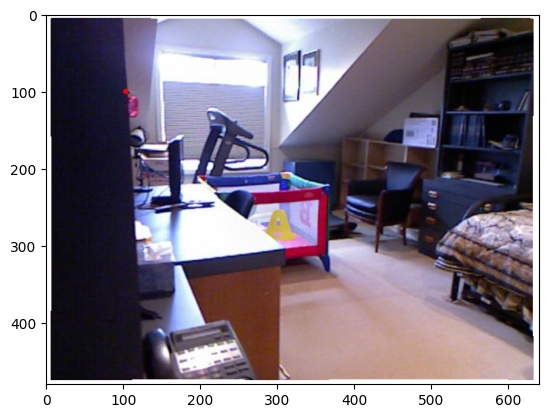

In [158]:
sample = df.sample()
print(sample)
img_pth = sample["rgb"].iloc[0]
print(sample["img"].iloc[0])
pred = model.predict(tf.expand_dims(sample["img"].iloc[0], axis=0))
x, y = pred[0][0], pred[0][1]
img = Image.open(img_pth)
draw = ImageDraw.Draw(img)
draw.ellipse((x-3,y-3, x+3, y+3), fill=255)
plt.imshow(img)


print("Predicted vanishing point:", pred)